In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pandas_datareader as data


plt.style.use('fivethirtyeight')
%matplotlib inline


In [2]:
import yfinance as yf
import datetime as dt

stock = "POWERGRID.NS"
start = dt.datetime(2000, 1, 1)
end = dt.datetime(2024, 11, 1)

df = yf.download(stock, start, end)

[*********************100%***********************]  1 of 1 completed


In [3]:
df.head()

Price,Close,High,Low,Open,Volume
Ticker,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS
Date,,,,,
2007-10-05,30.896231,33.629596,25.536993,27.579339,855215656
2007-10-08,29.314568,31.940440,29.130295,31.940440,126671715
2007-10-09,31.310846,31.587253,27.748259,29.329924,116725709
2007-10-10,31.602613,32.247565,31.326207,32.124716,67931378
2007-10-11,35.134480,36.854350,31.326198,36.854350,106320954


In [4]:
df.tail()

Price,Close,High,Low,Open,Volume
Ticker,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS
Date,,,,,
2024-10-25,297.992828,303.371431,295.586628,303.371431,12979410
2024-10-28,300.351898,302.380688,293.227634,296.766182,9610615
2024-10-29,302.475006,303.088377,296.435891,298.275947,15856332
2024-10-30,300.493439,307.051529,298.889286,300.587777,14498110
2024-10-31,302.710907,304.503794,299.927267,302.333468,9900390


In [5]:
df.shape

(4208, 5)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4208 entries, 2007-10-05 to 2024-10-31
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   (Close, POWERGRID.NS)   4208 non-null   float64
 1   (High, POWERGRID.NS)    4208 non-null   float64
 2   (Low, POWERGRID.NS)     4208 non-null   float64
 3   (Open, POWERGRID.NS)    4208 non-null   float64
 4   (Volume, POWERGRID.NS)  4208 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 197.2 KB


In [7]:
df.isnull().sum()

Price   Ticker      
Close   POWERGRID.NS    0
High    POWERGRID.NS    0
Low     POWERGRID.NS    0
Open    POWERGRID.NS    0
Volume  POWERGRID.NS    0
dtype: int64

In [8]:
df.describe()

Price,Close,High,Low,Open,Volume
Ticker,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS
count,4208.000000,4208.000000,4208.000000,4208.000000,4.208000e+03
mean,76.086376,77.075067,75.109494,76.121539,1.188963e+07
std,61.758299,62.480609,60.988900,61.740459,2.061999e+07
min,18.038855,19.282913,16.172767,19.189608,0.000000e+00
25%,34.678060,35.225168,34.165915,34.713579,4.799653e+06
50%,52.692305,53.300718,51.987139,52.793472,8.344398e+06
75%,78.901354,79.843159,77.965763,78.922817,1.362032e+07
max,344.843262,345.598106,337.058457,343.522181,8.552157e+08


In [9]:
df = df.reset_index()

In [10]:
df.shape

(4208, 6)

In [11]:
df.columns

MultiIndex([(  'Date',             ''),
            ( 'Close', 'POWERGRID.NS'),
            (  'High', 'POWERGRID.NS'),
            (   'Low', 'POWERGRID.NS'),
            (  'Open', 'POWERGRID.NS'),
            ('Volume', 'POWERGRID.NS')],
           names=['Price', 'Ticker'])

In [12]:
data01 = df.to_csv("powergrid.csv")

In [13]:
data01 = pd.read_csv("powergrid.csv")

In [14]:
data01.head()

,Price,Date,Close,High,Low,Open,Volume
0,Ticker,NaN,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS
1,0,2007-10-05,30.896230697631836,33.62959566682496,25.536993424027145,27.579339475363934,855215656
2,1,2007-10-08,29.31456756591797,31.940440009912148,29.13029501157929,31.940440009912148,126671715
3,2,2007-10-09,31.31084632873535,31.58725309319482,27.74825868243687,29.32992354655404,116725709
4,3,2007-10-10,31.60261344909668,32.24756542407025,31.32620664998688,32.12471633785299,67931378


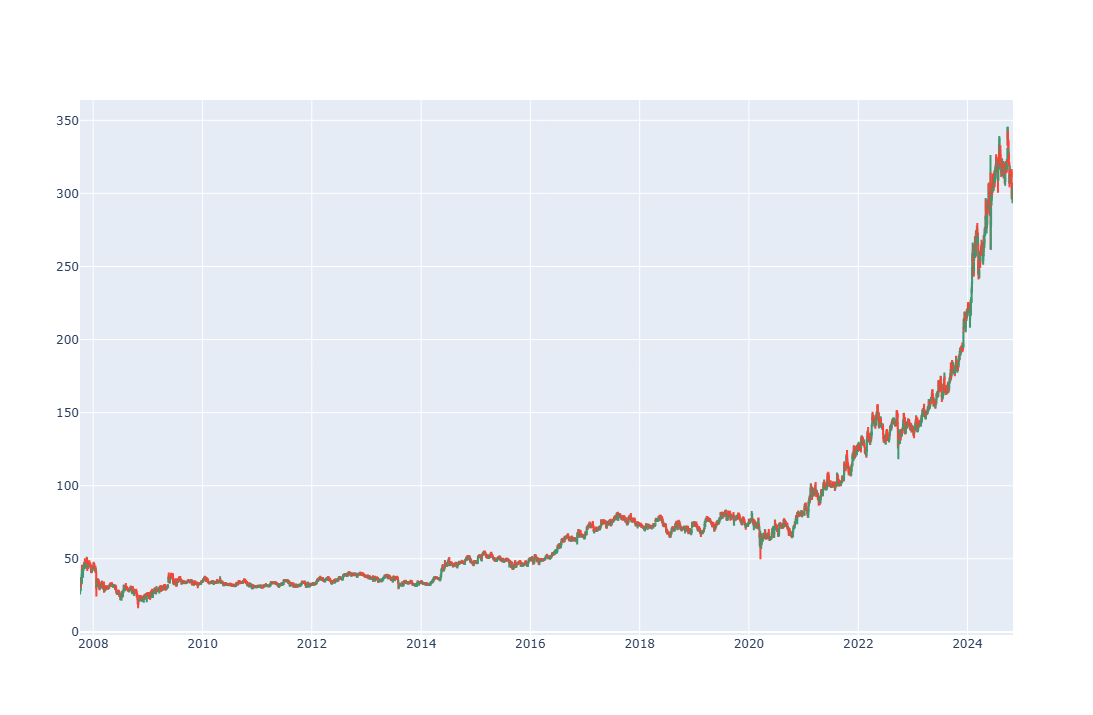

In [15]:
import plotly.graph_objects as go

fig = go.Figure(
    data=[
        go.Candlestick(
            x=data01['Date'],
            open=data01['Open'],
            high=data01['High'],
            low=data01['Low'],
            close=data01['Close']
        )
    ]
)

fig.update_layout(
    xaxis_rangeslider_visible=False,
    width=1200,
    height=700
)
fig.show()

In [16]:
df.head()

Price,Date,Close,High,Low,Open,Volume
Ticker,,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS,POWERGRID.NS
0,2007-10-05,30.896231,33.629596,25.536993,27.579339,855215656
1,2007-10-08,29.314568,31.940440,29.130295,31.940440,126671715
2,2007-10-09,31.310846,31.587253,27.748259,29.329924,116725709
3,2007-10-10,31.602613,32.247565,31.326207,32.124716,67931378
4,2007-10-11,35.134480,36.854350,31.326198,36.854350,106320954


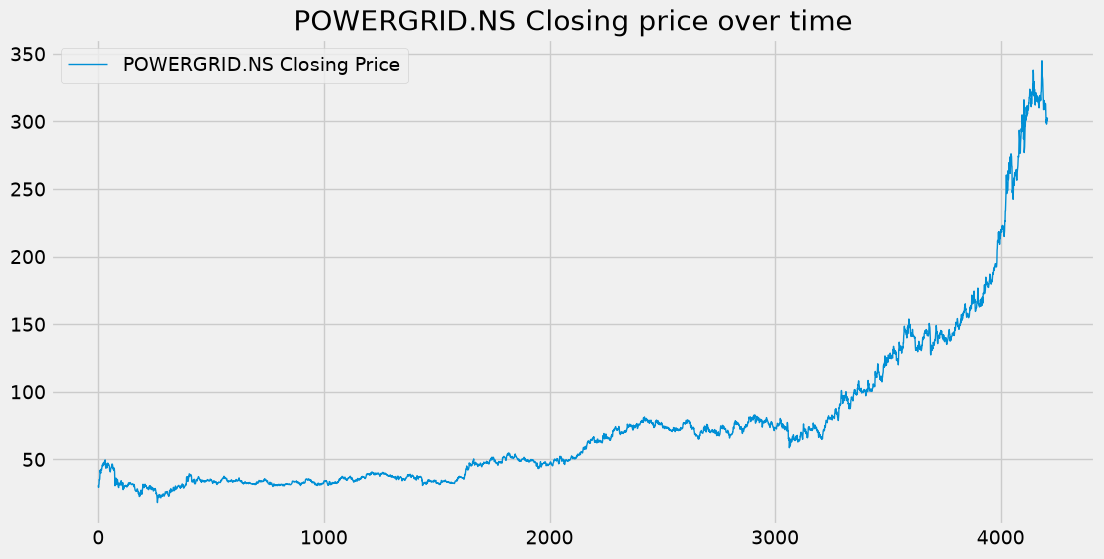

In [17]:
plt.figure(figsize=(12,6))
plt.plot(df.Close, label=f'{stock} Closing Price', linewidth=1)
plt.title(f'{stock} Closing price over time')
plt.legend()
plt.show()

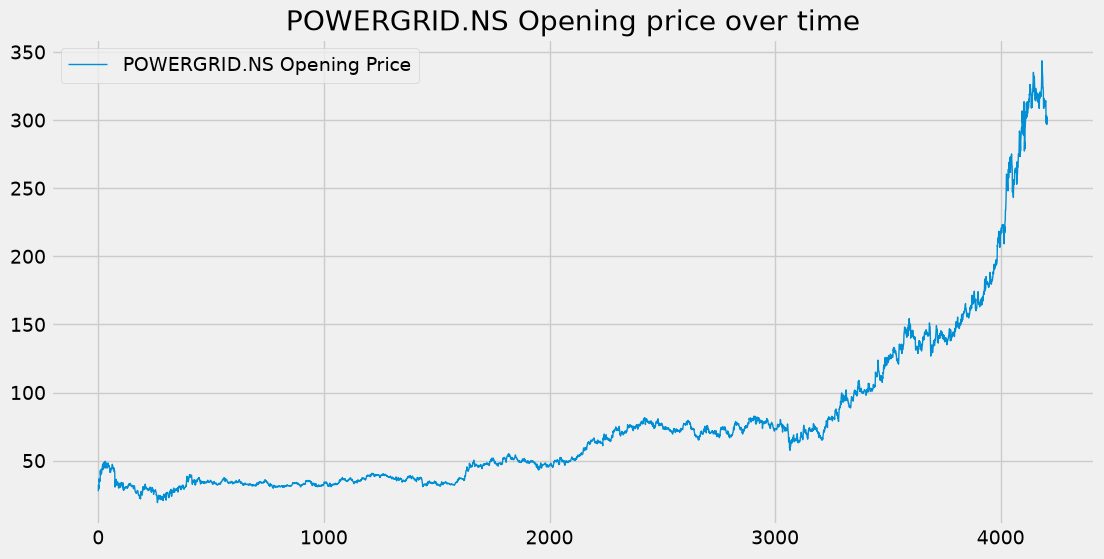

In [18]:
plt.figure(figsize=(12,6))
plt.plot(df.Open, label=f'{stock} Opening Price', linewidth=1)
plt.title(f'{stock} Opening price over time')
plt.legend()
plt.show()

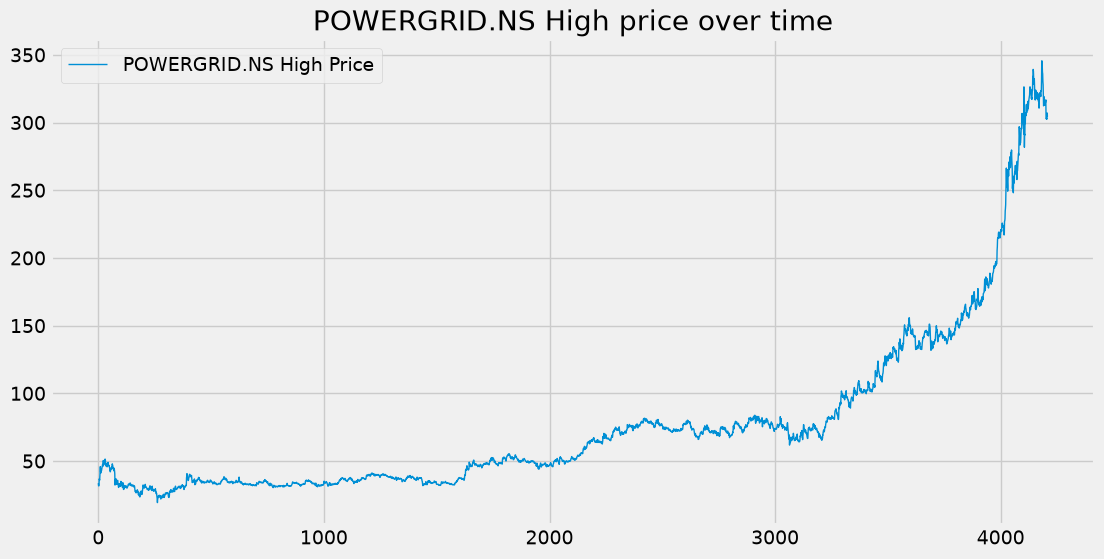

In [19]:
plt.figure(figsize=(12,6))
plt.plot(df.High, label=f'{stock} High Price', linewidth=1)
plt.title(f'{stock} High price over time')
plt.legend()
plt.show()

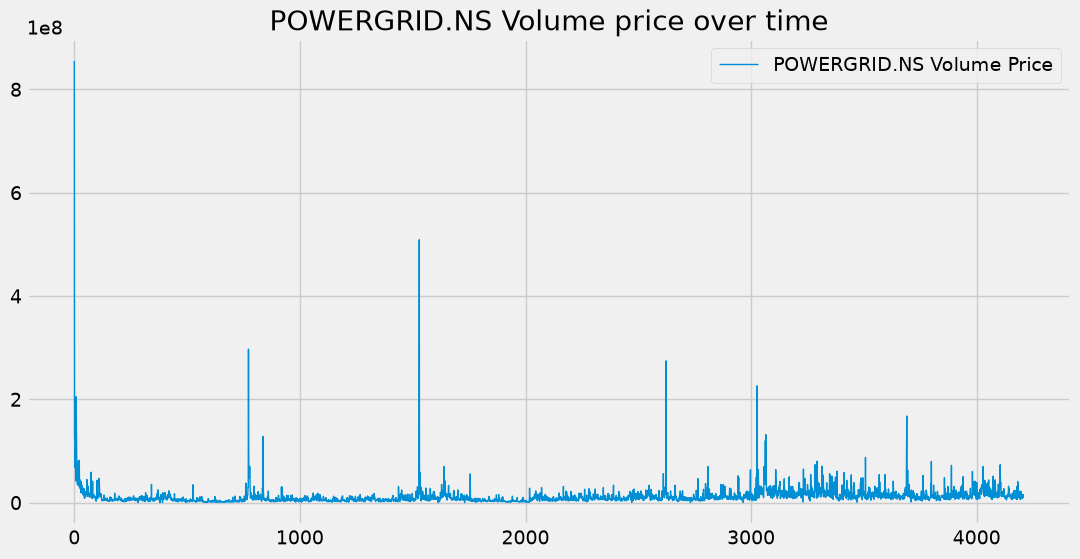

In [20]:
plt.figure(figsize=(12,6))
plt.plot(df.Volume, label=f'{stock} Volume Price', linewidth=1)
plt.title(f'{stock} Volume price over time')
plt.legend()
plt.show()

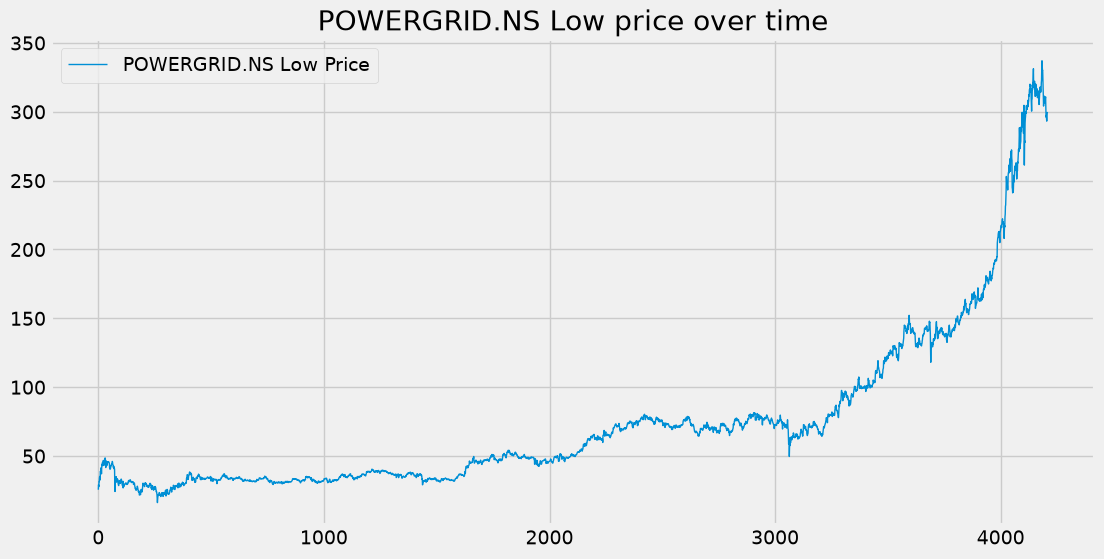

In [21]:
plt.figure(figsize=(12,6))
plt.plot(df.Low, label=f'{stock} Low Price', linewidth=1)
plt.title(f'{stock} Low price over time')
plt.legend()
plt.show()

In [22]:
ma100 = df.Close.rolling(100).mean()

In [23]:
ma100

Ticker,POWERGRID.NS
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
...,...
4203,314.707862
4204,314.941787
4205,315.170273
4206,315.363501


In [24]:
ma200 = df.Close.rolling(200).mean()

In [25]:
ma200

Ticker,POWERGRID.NS
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
...,...
4203,287.714211
4204,288.125015
4205,288.526186
4206,288.918370


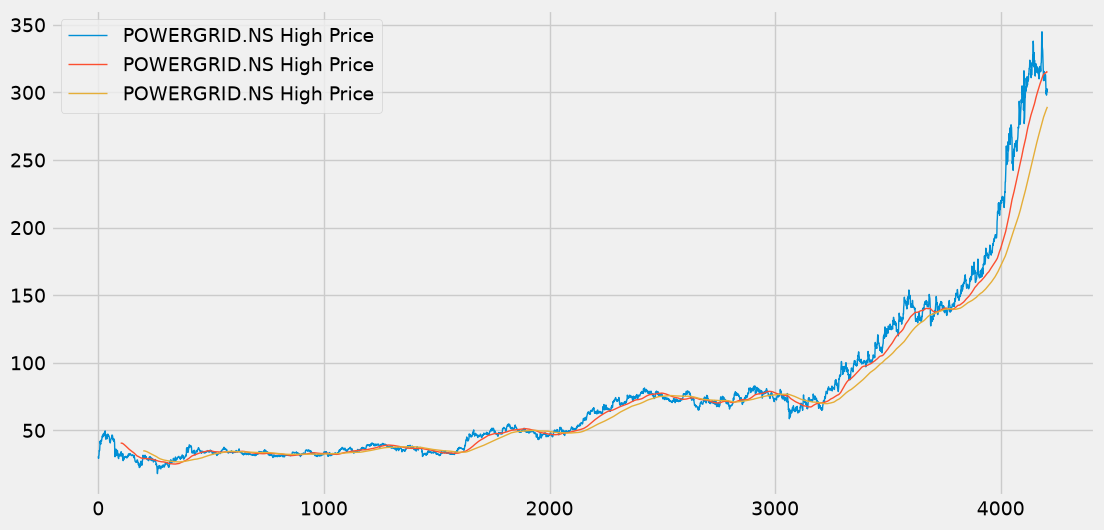

In [26]:
plt.figure(figsize=(12,6))
plt.plot(df.Close, label=f'{stock} High Price', linewidth=1)
plt.plot(ma100, label=f'{stock} High Price', linewidth=1)
plt.plot(ma200, label=f'{stock} High Price', linewidth=1)
plt.legend()
plt.show()

In [27]:
ema100 = df.Close.ewm(span=100, adjust=False).mean()

In [28]:
ema200 = df['Close'].ewm(span=200, adjust=False).mean()

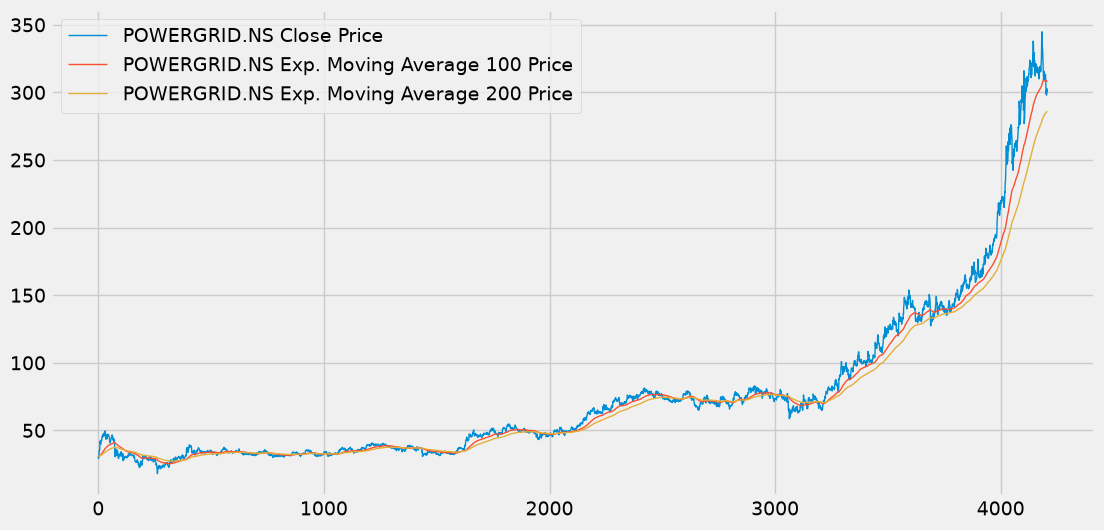

In [29]:
plt.figure(figsize=(12,6))
plt.plot(df.Close, label=f'{stock} Close Price', linewidth=1)
plt.plot(ema100, label=f'{stock} Exp. Moving Average 100 Price', linewidth=1)
plt.plot(ema200, label=f'{stock} Exp. Moving Average 200 Price', linewidth=1)
plt.legend()
plt.show()

In [30]:
data_training = pd.DataFrame(df['Close'][0:int(len(df)*0.70)])
data_testing = pd.DataFrame(df['Close'][int(len(df)*0.70): int(len(df))])

In [31]:
data_training.shape

(2945, 1)

In [32]:
data_testing.shape

(1263, 1)

In [33]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0,1))

In [34]:
data_training_array = scaler.fit_transform(data_training)

In [35]:
data_training_array

array([[0.19808592],
       [0.17371818],
       [0.20447366],
       ...,
       [0.90774447],
       [0.86000369],
       [0.87299638]], shape=(2945, 1))

In [36]:
X_train = []
y_train = []

for i in range(100, data_training_array.shape[0]):
    X_train.append(data_training_array[i-100:i])
    y_train.append(data_training_array[i,0])

X_train, y_train = np.array(X_train), np.array(y_train)

In [37]:
X_train.shape

(2845, 100, 1)

In [44]:
from keras.layers import Dense, Dropout, LSTM, Input
from keras.models import Sequential

In [60]:
model = Sequential()

model.add(Input(shape=(X_train.shape[1], 1)))

model.add(LSTM(units=50, activation='relu', return_sequences=True))
model.add(Dropout(0.2))

model.add(LSTM(units=60, activation='relu', return_sequences=True))
model.add(Dropout(0.3))

model.add(LSTM(units=80, activation='relu', return_sequences=True))
model.add(Dropout(0.4))

model.add(LSTM(units=120, activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(units=1))

In [61]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_8 (LSTM)                        │ (None, 100, 50)             │          10,400 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_8 (Dropout)                  │ (None, 100, 50)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_9 (LSTM)                        │ (None, 100, 60)             │          26,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_9 (Dropout)                  │ (None, 100, 60)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_10 (LSTM)                       │ (None, 100, 80)             │          45,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_10 (Dropout)                 │ (None, 100, 80)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_11 (LSTM)                       │ (None, 120)                 │          96,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_11 (Dropout)                 │ (None, 120)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │             121 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 178,761 (698.29 KB)

 Trainable params: 178,761 (698.29 KB)

 Non-trainable params: 0 (0.00 B)

In [62]:
model.compile(optimizer='adam', loss='mean_squared_error')
model.fit(X_train, y_train, epochs=50)

Epoch 1/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 19s 132ms/step - loss: 0.0275
Epoch 2/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 14s 157ms/step - loss: 0.0073
Epoch 3/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 15s 165ms/step - loss: 0.0063
Epoch 4/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 14s 159ms/step - loss: 0.0058
Epoch 5/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 14s 154ms/step - loss: 0.0056
Epoch 6/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 13s 151ms/step - loss: 0.0054
Epoch 7/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 15s 165ms/step - loss: 0.0044
Epoch 8/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 18s 198ms/step - loss: 0.0046
Epoch 9/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 14s 159ms/step - loss: 0.0047
Epoch 10/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 14s 153ms/step - loss: 0.0041
Epoch 11/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 14s 153ms/step - loss: 0.0041
Epoch 12/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 14s 152ms/step - loss: 0.0040
Epoch 13/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 14s 152ms/step - loss: 0.0038
Epoch 14/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 14s 152ms/step - loss: 0.0038
Epoch 15/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 14s 

In [63]:
past_100_days = data_training.tail(100)

In [64]:
final_df = pd.concat([past_100_days, data_testing], ignore_index=True)

In [65]:
input_data = scaler.fit_transform(final_df)

In [66]:
X_test = []
y_test = []

for i in range(100, input_data.shape[0]):
    X_test.append(input_data[i-100:i])
    y_test.append(input_data[i,0])

X_test, y_test = np.array(X_test), np.array(y_test)

In [67]:
X_test.shape

(1263, 100, 1)

In [68]:
y_predicted = model.predict(X_test)

40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 63ms/step


In [69]:
y_predicted.shape

(1263, 1)

In [70]:
scaler.scale_

array([0.00349382])

In [75]:
scaler_factor = 1 / 0.0035166
y_predicted = y_predicted * scaler_factor
y_test = y_test * scaler_factor

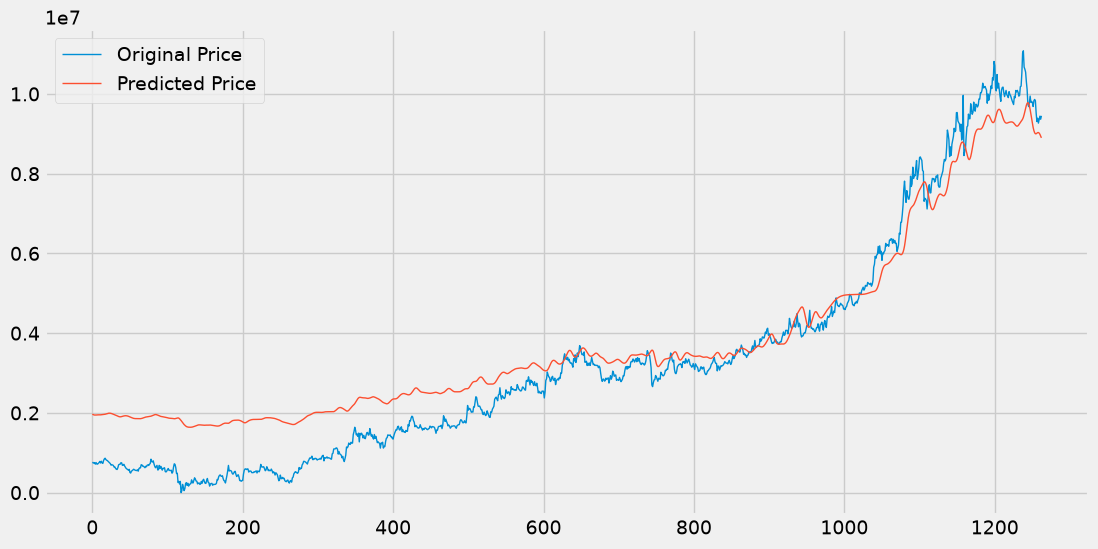

In [78]:
plt.figure(figsize=(12,6))
plt.plot(y_test, label='Original Price', linewidth=1)
plt.plot(y_predicted, label='Predicted Price', linewidth=1)
plt.legend()
plt.show()

In [77]:
model.save('stock_dl_model.keras')